# Exploración de datos
---

**Autor:** Jaime Lozano Cillero

# 0. Preparación del entorno

In [1]:
from dotenv import load_dotenv
import getpass
import os
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from openai import OpenAI

load_dotenv()

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

GENERATION_MODEL = os.getenv("OPENAI_GENERATION_MODEL", "gpt-4.1-mini")
EMBEDDING_MODEL = os.getenv("OPENAI_EMBEDDING_MODEL", "text-embedding-3-small")

client = OpenAI()

RAG_K = 5

PDF_PATH = Path("../../data/raw/TENERIFE.pdf")

print("Modelo generativo:", GENERATION_MODEL)
print("Modelo de embeddings:", EMBEDDING_MODEL)
print("PDF:", PDF_PATH.resolve())

Modelo generativo: gpt-4.1-mini
Modelo de embeddings: text-embedding-3-small
PDF: C:\Users\Jaime\Documents\Pontia\modulo-06-llms\entrega-final\pontia-llms-entrega-final\data\raw\TENERIFE.pdf


In [2]:
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings

llm = init_chat_model(
    GENERATION_MODEL,
    model_provider="openai",
    temperature=0.1,
    max_tokens=1000,
)
embeddings = OpenAIEmbeddings(model=EMBEDDING_MODEL)

# 1. Carga de datos

Se usará el fichero PDF local: `data/raw/TENERIFE.pdf`.

El objetivo es que el contenido acabe convertido en objetos `Document`, que tienen dos partes:

- `page_content`: el texto del documento.
- `metadata`: información adicional, como fuente, página, ruta, fecha, categoría, etc.

In [3]:
from pypdf import PdfReader
from langchain_core.documents import Document

if not PDF_PATH.exists():
    raise FileNotFoundError(f"No se encontró el PDF en {PDF_PATH.resolve()}")

reader = PdfReader(str(PDF_PATH))

docs = [
    Document(
        page_content=page.extract_text().strip(),
        metadata={
            "source": str(PDF_PATH),
            "page": page_number,
            "page_label": reader.page_labels[page_number],
            "total_pages": len(reader.pages),
        },
    )
    for page_number, page in enumerate(reader.pages)
]

print("Número de páginas cargadas:", len(docs))
print("Metadata de la primera página:", docs[0].metadata)
print("Primeros caracteres:\n")
print(docs[0].page_content[:512])

Número de páginas cargadas: 25
Metadata de la primera página: {'source': '..\\..\\data\\raw\\TENERIFE.pdf', 'page': 0, 'page_label': '1', 'total_pages': 25}
Primeros caracteres:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler -


In [4]:
print(docs[7].page_content)

o Playa de Benijo [vídeo - ubicación] 
Playa de arena negra, si el día está despejado, de los atardeceres más 
espectaculares que podéis ver en la isla. 
Para llegar a esta playa, aparcar por aquí y, para acceder a la playa, se accede 
desde aquí (puede ser que os encontréis con el acceso cortado con una valla, 
pero da igual, podéis acceder igualmente). 
• La Orotava 
Este es el pueblo más bonito y maravilloso del mundo (no es porque yo sea de allí).


In [5]:
print(reader.metadata)
print(reader.page_layout)
print(reader.page_mode)

{'/Title': 'Microsoft Word - TENERIFE.docx', '/Creator': 'Microsoft Word', '/CreationDate': "D:20250713200001+00'00'", '/ModDate': "D:20250713200001+00'00'"}
None
None


# 2. Chunking

## 2.1 Estrategia 1

### 2.1.1 Chunking

In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=80,
    add_start_index=True,
)

splits = text_splitter.split_documents(docs)

# Añadimos un identificador simple a cada chunk para poder citarlo luego.
for i, doc in enumerate(splits):
    doc.metadata["chunk_id"] = i
    doc.metadata["source_name"] = PDF_PATH.name

print("Número de chunks:", len(splits))
print("\nEjemplo de chunk:\n")
print(splits[0].page_content)
print("\nMetadata:", splits[0].metadata)

Número de chunks: 47

Ejemplo de chunk:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo

Metadata: {'source': '..\\..\\data\\raw\\TENERIFE.pdf', 'page': 0, 'page_label': '1', 'total_pages': 25, 'start_index': 0, 'chunk_id': 0, 'source_name': 'TENERIFE.pdf'}


### 2.1.1 Embeddings y vector store

El objetivo del RAG es recuperar información relacionada con las consultas variables del usuario. Para ello, necesitamos comparar el signficado de la pregunta con el significado de nuestros textos (chunks) para recuperar los que sean más parecidos. Esos chunks recuperados serán provistos al LLM como contexto de tal manera que lo integre en su respuesta al usuario y dé como resultado una respuesta relevante.

Para poder comparar significados, cada texto será transformado a embedding y se compararán usando una medida de similaridad.

Se usará la clase `InMemoryVectorStore` para la transformación y almacenamiento de los embeddings en memoria.

In [7]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)
document_ids = vector_store.add_documents(splits)

print("Documentos indexados:", len(document_ids))
print("Primeros IDs:", document_ids[:3])

Documentos indexados: 47
Primeros IDs: ['82b5a414-cd3f-4d58-848f-ca250561156e', '4a62fa85-7b1c-496f-9e19-52cb43f7268f', '6cb9baa5-85d8-4879-b715-970cbd54bce9']


### 2.1.2 Recuperación 

Comprobar el mecanismo de recuperación para verificar que se recuperan chunks relevantes con la consulta del usuario.

In [8]:
def mostrar_documentos_recuperados(documentos):
    for i, doc in enumerate(documentos, start=1):
        print(f"Resultado {i}")
        print("Fuente:", doc.metadata.get("source_name"))
        print("Página:", doc.metadata.get("page"))
        print("Chunk:", doc.metadata.get("chunk_id"))
        print(doc.page_content)
        print("-" * 80)

pregunta = "¿Dònde puedo comer sushi en Tenerife?"
retrieved_docs = vector_store.similarity_search(pregunta, k=3)

mostrar_documentos_recuperados(retrieved_docs)

Resultado 1
Fuente: TENERIFE.pdf
Página: 24
Chunk: 45
▪ Arepera La Carajita (entre La Orotava y el Puerto de la Cruz 
[ubicación]. Este sitio tiene las mejores arepas que podréis comer en 
vuestra vida y son baratísimas. Recomendación: La Fogalera y Reina 
Pepiada. Y pedir de entrantes una degustación de cachapitas). 
Importante ir con hambre.  
▪ Atuvera (entre La Orotava y el Puerto de la Cruz [ubicación]). 
Recomendable reservar. 
▪ Restaurante Fujiyama (sushi en la zona de Santa Cruz [ubicación])
--------------------------------------------------------------------------------
Resultado 2
Fuente: TENERIFE.pdf
Página: 23
Chunk: 44
El Paraíso (espectacular la salsa de aguacate de aquí. 
Recomendación: menú feliz de bocadillo de pollo + Nestea de 
mango-piña) - Cafetería Zumería Mango - El Track 
 
 
Nota:   los bocadillos de pollo del norte de Tenerife no son como los bocadillos 
que se hacen en otros lugares de España.   Recomiendo que lo prueben, está 
increíble.
-------------------

### 2.1.3 Análisis de la recuperación RAG

Métricas clave:
- Hit Rate@k: Proporción de consultas donde al menos un fragmento relevante aparece en los $k$ documentos recuperados.

- MRR@k (Mean Reciprocal Rank): Penaliza si el documento relevante aparece en posiciones inferiores del ranking:$$\text{MRR} = \frac{1}{\vert{}Q\vert{}} \sum_{i=1}^{\vert{}Q\vert{}} \frac{1}{\text{rank}_i}$$

    k  Hit Rate       MRR
0   1       0.0  0.000000
1   2       0.0  0.000000
2   4       0.4  0.116667
3   6       0.6  0.156667
4   8       0.6  0.156667
5  10       0.6  0.156667


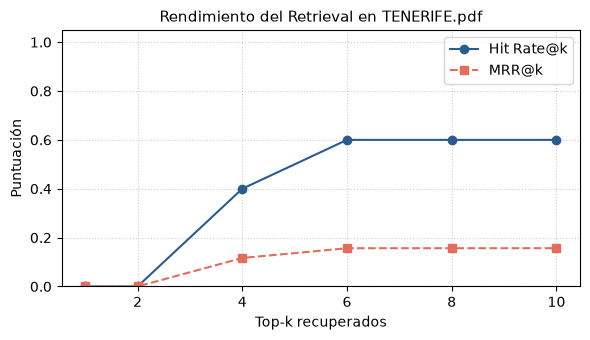

In [9]:
# 1. Dataset de prueba sobre TENERIFE.pdf
EVAL_DATASET = [
    {
        "query": "¿En qué municipio está el Lago Martiánez y quién lo diseñó?",
        "expected_page": 4,
        "keywords": ["Puerto de la Cruz", "César Manrique"],
    },
    {
        "query": "¿Qué particularidad tiene el reloj de la Iglesia de la Concepción de La Laguna?",
        "expected_page": 3,
        "keywords": ["IIII", "reloj"],
    },
    {
        "query": "¿Cómo se accede a Punta de Teno actualmente?",
        "expected_page": 14,
        "keywords": ["guagua", "369", "Titsa"],
    },
    {
        "query": "¿Qué se come en La Cueva de Casiano?",
        "expected_page": 24,
        "keywords": ["batata", "almogrote"],
    },
    {
        "query": "¿Qué guachinche auténtico no tiene carta?",
        "expected_page": 24,
        "keywords": ["El Cubano", "vino", "Seven Up"],
    },
]


def evaluate_retrieval(vector_store, dataset: list[dict], k_values=(1, 2, 4, 6, 8, 10)):
    """Calcula Hit Rate@k y MRR@k para diferentes profundidades de búsqueda."""
    results = {k: {"hits": 0, "reciprocal_ranks": []} for k in k_values}

    for item in dataset:
        for k in k_values:
            retrieved = vector_store.similarity_search(item["query"], k=k)
            retrieved_pages = [doc.metadata.get("page") for doc in retrieved]

            # Verificación de acierto
            expected = item["expected_page"]
            if expected in retrieved_pages:
                results[k]["hits"] += 1
                rank = retrieved_pages.index(expected) + 1
                results[k]["reciprocal_ranks"].append(1.0 / rank)
            else:
                results[k]["reciprocal_ranks"].append(0.0)

    total = len(dataset)
    metrics_summary = []
    for k in k_values:
        hit_rate = results[k]["hits"] / total
        mrr = sum(results[k]["reciprocal_ranks"]) / total
        metrics_summary.append({"k": k, "Hit Rate": hit_rate, "MRR": mrr})

    return pd.DataFrame(metrics_summary)


# Ejecución y visualización
df_metrics = evaluate_retrieval(vector_store, EVAL_DATASET)
print(df_metrics)

# Gráfico para el notebook
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(df_metrics["k"], df_metrics["Hit Rate"], marker="o", label="Hit Rate@k", color="#2b5c8f")
ax.plot(df_metrics["k"], df_metrics["MRR"], marker="s", linestyle="--", label="MRR@k", color="#e26d5c")
ax.set_title("Rendimiento del Retrieval en TENERIFE.pdf", fontsize=11)
ax.set_xlabel("Top-k recuperados")
ax.set_ylabel("Puntuación")
ax.set_ylim(0, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

## 2.2 Estrategia 2

## 2.2.1 Chunking

In [10]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    add_start_index=True,
    separators=[
        "\n\n",       # Saltos de bloque grandes
        "\n• ",       # Secciones principales (municipios/zonas)
        "\n▪ ",       # Sub-elementos (restaurantes, areperas)
        "\n- ",       # Pasos de rutas o itinerarios
        "\n o ",      # Puntos de interés específicos
        "\n",         # Saltos de línea simples
        ". ",         # Frases
        " ",          # Palabras
    ],
)

splits = text_splitter.split_documents(docs)

# Añadimos un identificador simple a cada chunk para poder citarlo luego.
for i, doc in enumerate(splits):
    doc.metadata["chunk_id"] = i
    doc.metadata["source_name"] = PDF_PATH.name

print("Número de chunks:", len(splits))
print("\nEjemplo de chunk:\n")
print(splits[0].page_content)
print("\nMetadata:", splits[0].metadata)

Número de chunks: 33

Ejemplo de chunk:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler - ubicación –; ir hacia el Parque García Sanabria - 
ubicación -; y bajar de nuevo hacia Plaza de España pasando por la Plaza del 
Príncipe - ubicación). 
- Volver de nuevo a por el coche. 
- Ir hacia la playa de Las Teresitas (ubicación). 
Los puntos de interés sugeridos son estos: 
o Parque Marítimo César Manrique [vídeo - ubicación] 
Conjunto de piscinas naturales.

Metadata: {'source': '..\\..\\data\\raw\\TENERIFE.pdf', 'page': 0, 'page_lab

### 2.2.1 Embeddings y vector store

El objetivo del RAG es recuperar información relacionada con las consultas variables del usuario. Para ello, necesitamos comparar el signficado de la pregunta con el significado de nuestros textos (chunks) para recuperar los que sean más parecidos. Esos chunks recuperados serán provistos al LLM como contexto de tal manera que lo integre en su respuesta al usuario y dé como resultado una respuesta relevante.

Para poder comparar significados, cada texto será transformado a embedding y se compararán usando una medida de similaridad.

Se usará la clase `InMemoryVectorStore` para la transformación y almacenamiento de los embeddings en memoria.

In [11]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)
document_ids = vector_store.add_documents(splits)

print("Documentos indexados:", len(document_ids))
print("Primeros IDs:", document_ids[:3])

Documentos indexados: 33
Primeros IDs: ['79c3740d-423f-4cef-ae33-69c5dac2dff8', '25687959-ac0c-4853-9fa2-fbad0a0a4a94', '13fe2381-32c7-44b8-a925-c682063d98ac']


### 2.2.2 Recuperación 

Comprobar el mecanismo de recuperación para verificar que se recuperan chunks relevantes con la consulta del usuario.

In [12]:
def mostrar_documentos_recuperados(documentos):
    for i, doc in enumerate(documentos, start=1):
        print(f"Resultado {i}")
        print("Fuente:", doc.metadata.get("source_name"))
        print("Página:", doc.metadata.get("page"))
        print("Chunk:", doc.metadata.get("chunk_id"))
        print(doc.page_content)
        print("-" * 80)

pregunta = "¿Dònde puedo comer sushi en Tenerife?"
retrieved_docs = vector_store.similarity_search(pregunta, k=3)

mostrar_documentos_recuperados(retrieved_docs)

Resultado 1
Fuente: TENERIFE.pdf
Página: 23
Chunk: 31
▪ Pizzería Gioconda (zona de La Orotava [ubicación]) [Tripadvisor] 
▪ El Palestra (zona de La Orotava [ubicación]. Este es el típico sitio que 
ha estado toda la vida en La Orotava y que te pides a domicilio cuando 
tienes el antojo. Nosotros solo pedimos una cosa: Plato feliz de pizza + 
Nestea de mango-piña para beber. [Tripadvisor] 
▪ Sitios de bocadillos top: Cafetería Deyfe - Bar-Cafetería Australia - Bar 
El Paraíso (espectacular la salsa de aguacate de aquí. 
Recomendación: menú feliz de bocadillo de pollo + Nestea de 
mango-piña) - Cafetería Zumería Mango - El Track 
 
 
Nota:   los bocadillos de pollo del norte de Tenerife no son como los bocadillos 
que se hacen en otros lugares de España.   Recomiendo que lo prueben, está 
increíble.
--------------------------------------------------------------------------------
Resultado 2
Fuente: TENERIFE.pdf
Página: 24
Chunk: 32
▪ Arepera La Carajita (entre La Orotava y el Puerto de l

### 2.1.3 Análisis de la recuperación RAG

Métricas clave:
- Hit Rate@k: Proporción de consultas donde al menos un fragmento relevante aparece en los $k$ documentos recuperados.

- MRR@k (Mean Reciprocal Rank): Penaliza si el documento relevante aparece en posiciones inferiores del ranking:$$\text{MRR} = \frac{1}{\vert{}Q\vert{}} \sum_{i=1}^{\vert{}Q\vert{}} \frac{1}{\text{rank}_i}$$

    k  Hit Rate    MRR
0   1       0.0  0.000
1   2       0.2  0.100
2   4       0.2  0.100
3   6       0.6  0.180
4   8       0.8  0.205
5  10       0.8  0.205


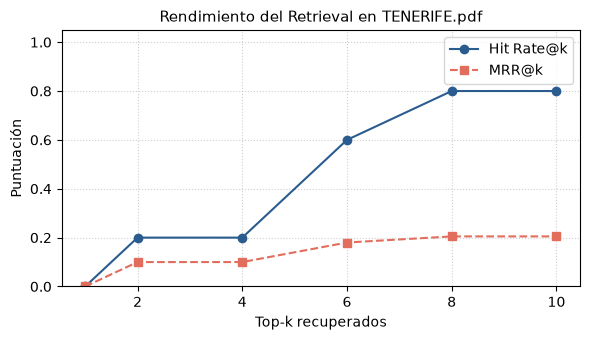

In [13]:
# Ejecución y visualización
df_metrics = evaluate_retrieval(vector_store, EVAL_DATASET)
print(df_metrics)

# Gráfico para el notebook
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(df_metrics["k"], df_metrics["Hit Rate"], marker="o", label="Hit Rate@k", color="#2b5c8f")
ax.plot(df_metrics["k"], df_metrics["MRR"], marker="s", linestyle="--", label="MRR@k", color="#e26d5c")
ax.set_title("Rendimiento del Retrieval en TENERIFE.pdf", fontsize=11)
ax.set_xlabel("Top-k recuperados")
ax.set_ylabel("Puntuación")
ax.set_ylim(0, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

# 5. Añadir los chunks al contexto del LLM

Se añaden los chunks recuperados al prompt que se envía al LLM.

Queremos que el modelo:

1. Responda usando solo el contexto.
2. Diga que no tiene información si el contexto no contiene la respuesta.
3. Cite las fuentes utilizadas.

In [19]:
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Eres un guía turístico con más de 20 años de experiencia en la isla Tenerife."
            "Responde en español utilizando expresiones típicas canarias y usando únicamente el contexto proporcionado."
            "Si el contexto no contiene la respuesta, di claramente: 'No tengo información suficiente en la base documental'. "
            "No inventes datos. Cita las fuentes usadas al final.",
        ),
        (
            "user",
            "Pregunta:\n{question}\n\nContexto recuperado:\n{context}\n\nRespuesta:",
        ),
    ]
)

In [20]:
def format_docs_with_sources(documentos):
    bloques = []
    for i, doc in enumerate(documentos, start=1):
        source = doc.metadata.get("source_name", "fuente desconocida")
        page = doc.metadata.get("page", "?")
        chunk_id = doc.metadata.get("chunk_id", "?")
        bloques.append(
            f"[Fuente {i}: {source}, página {page}, chunk {chunk_id}]\n{doc.page_content}"
        )
    return "\n\n".join(bloques)


def answer_with_rag(question: str, k: int = 3, show_context: bool = False):
    retrieved_docs = vector_store.similarity_search(question, k=k)
    context = format_docs_with_sources(retrieved_docs)

    if show_context:
        print("CONTEXTO RECUPERADO")
        print(context)
        print("=" * 80)

    messages = rag_prompt.invoke({"question": question, "context": context})
    answer = llm.invoke(messages)

    return {
        "question": question,
        "answer": answer.content,
        "context": retrieved_docs,
        "prompt": messages,
    }

In [21]:
result = answer_with_rag(
    pregunta,
    k=RAG_K,
    show_context=True,
)

print(result["answer"])

CONTEXTO RECUPERADO
[Fuente 1: TENERIFE.pdf, página 23, chunk 31]
▪ Pizzería Gioconda (zona de La Orotava [ubicación]) [Tripadvisor] 
▪ El Palestra (zona de La Orotava [ubicación]. Este es el típico sitio que 
ha estado toda la vida en La Orotava y que te pides a domicilio cuando 
tienes el antojo. Nosotros solo pedimos una cosa: Plato feliz de pizza + 
Nestea de mango-piña para beber. [Tripadvisor] 
▪ Sitios de bocadillos top: Cafetería Deyfe - Bar-Cafetería Australia - Bar 
El Paraíso (espectacular la salsa de aguacate de aquí. 
Recomendación: menú feliz de bocadillo de pollo + Nestea de 
mango-piña) - Cafetería Zumería Mango - El Track 
 
 
Nota:   los bocadillos de pollo del norte de Tenerife no son como los bocadillos 
que se hacen en otros lugares de España.   Recomiendo que lo prueben, está 
increíble.

[Fuente 2: TENERIFE.pdf, página 24, chunk 32]
▪ Arepera La Carajita (entre La Orotava y el Puerto de la Cruz 
[ubicación]. Este sitio tiene las mejores arepas que podréis comer e

Probamos a preguntar algo un poco difuso:

In [22]:
result = answer_with_rag(
    "Me gustaría bañarme en el mar",
    k=RAG_K,
    show_context=True,
)

print(result["answer"])

CONTEXTO RECUPERADO
[Fuente 1: TENERIFE.pdf, página 19, chunk 22]
o Playa del Camisón 
Esta es una playa pequeñita que a nosotros en concreto nos gusta mucho.

[Fuente 2: TENERIFE.pdf, página 10, chunk 10]
tendréis poca playa (especialmente a la del Ancón) y tened mucho respeto al mar en 
estas playas, que la corriente es muy traicionera.

[Fuente 3: TENERIFE.pdf, página 9, chunk 9]
o La Playa de Los Patos 
o Playa del Ancón 
 
Nota: Para llegar estas playas hay que caminar un rato y algunas son de difícil acceso 
(la de Los Patos). También hay que ir a estas playas cuando la marea esté baja, si no

[Fuente 4: TENERIFE.pdf, página 22, chunk 26]
• El Médano / La Tejita 
Playas tipiquísimas de Tenerife y otra de las estampas de la isla con Montaña Roja al 
fondo. Nota: La Tejita es playa nudista para que lo tengáis en cuenta.  
 
 
• Los Cristianos 
De la zona de Los Cristianos que me venga a la mente os recomendaría la Playa de 
Los Cristianos o la Playa de Las Vistas y creo que poco má

Probamos a preguntar algo que no incluye la fuente documental.

In [23]:
result = answer_with_rag(
    "Me gustaría ir a un circuito de Formula 1",
    k=RAG_K,
)

print(result["answer"])

¡Mi niño, en Tenerife no hay circuito de Fórmula 1, así que no vas a poder disfrutar de una carrera oficial aquí en la isla! Eso sí, si te gusta la velocidad y las pelis de coches, te cuento que en la carretera de Punta de Teno se grabó el principio de la película Fast & Furious 6, que es un puntazo para los amantes del motor y la acción [Fuente 1]. 

Si quieres vivir emociones fuertes, te recomiendo más bien visitar el Siam Park en Costa Adeje, que es un parque acuático de récord mundial y seguro que te lo pasas de lujo [Fuente 4]. Pero para circuitos de Fórmula 1, tendrás que buscar en otro sitio, porque aquí en Tenerife no hay.

¡Espero que te sirva, mi niño! Si quieres que te cuente más cositas de la isla, aquí estoy para ayudarte.

Fuentes:
- [Fuente 1: TENERIFE.pdf, página 13]
- [Fuente 4: TENERIFE.pdf, página 20]
